# 🧪 Notebook 10 — Variational Quantum Eigensolver

> **Module:** Quantum Computing for Computational Chemistry\
> **Level:** Intermediate–Advanced\
> **Estimated time:** 90 min\
> **Prerequisites:** Hamiltonian mapping, Pauli measurement, SciPy optimization, and parameterized Qiskit circuits

---

## 📌 Overview

This notebook implements a simple VQE to compute the ground state of a molecular Hamiltonian
using hardware-efficient and UCC-inspired ansätze.


## 🎯 Learning objectives

By the end of this notebook, you should be able to:

- Explain the variational principle and VQE workflow.
- Construct and compare parameterized ansätze.
- Estimate Hamiltonian energies from measured Pauli terms.
- Optimize circuit parameters and analyze convergence.

## 🔑 Key concepts

`VQE` · `variational principle` · `ansatz` · `COBYLA` · `shot noise` · `UCC` · `spin symmetry`

## 🧩 Structure

1. Hamiltonian construction
2. Number-conserving ansatz
3. Measured energy
4. Optimization
5. UCC-inspired circuits and diagnostics

## 📚 Resources

- PySCF, OpenFermion, Qiskit, and SciPy documentation
- Reference: Peruzzo *et al.*, *A variational eigenvalue solver on a photonic quantum processor* (2014)
- Previous notebook: `qft.ipynb`

### ⏱️ Expected outcome

You will implement VQE using different ansatz and obtain the ground state energy of H2.

# Variational quantum eigensolver (VQE) ansatz

The two-qubit circuit prepares a trial state $|\psi(\boldsymbol{\theta})\rangle$. Independent $R_y$ rotations create adjustable single-qubit amplitudes, and the CNOT creates entanglement. Binding numerical values to the four parameters produces one concrete circuit whose computational-basis measurement probabilities can be sampled.

VQE minimizes the variational energy

$$E(\boldsymbol{\theta})=\langle\psi(\boldsymbol{\theta})|H_{\mathrm{qubit}}|\psi(\boldsymbol{\theta})\rangle. $$

In [1]:
import numpy as np
from openfermion import FermionOperator, QubitOperator, jordan_wigner

## Molecular Hamiltonian and exact reference

In [2]:
# H2 molecule
from pyscf import gto, scf

# Build molecule
mol = gto.M(
    atom=[["H", (0.0, 0.0, 0.0)],
          ["H", (0.0, 0.0, 0.74)]],
    basis="sto-3g",
    unit="Angstrom",
)

# Hartree-Fock calculation
mf = scf.RHF(mol)
mf.kernel()

converged SCF energy = -1.11675930739643


np.float64(-1.1167593073964255)

The molecular integrals are transformed from spatial orbitals to spin orbitals and stored in an `InteractionOperator`. In second quantization,

$$H=E_{\mathrm{nuc}}+\sum_{pq}h_{pq}a_p^\dagger a_q+\frac{1}{2}\sum_{pqrs}h_{pqrs}a_p^\dagger a_q^\dagger a_r a_s. $$

The sparse matrix diagonalization and PySCF FCI calculation provide exact reference energies against which the VQE estimates can be compared.

In [3]:
from pyscf import ao2mo

C = mf.mo_coeff

# One-electron integrals in MO basis
h1 = mf.get_hcore() # Core Hamiltonian (kinetic + nuclear attraction)
h1_mo = C.T @ h1 @ C

# Two-electron integrals in MO basis (Electron Repulsion Integrals)
eri_mo = ao2mo.kernel(mol, C)
eri_mo = ao2mo.restore(1, eri_mo, C.shape[1])
# h[p,q,r,s] = (ps|qr)
eri_mo = eri_mo.transpose(0, 2, 3, 1)

e_nuc = mf.energy_nuc()

# 1 electron integrals
print(h1_mo)
# 2 electron integrals
print(eri_mo)
print(e_nuc)

[[-1.25330979e+00 -2.16420228e-16]
 [-4.69718139e-16 -4.75068849e-01]]
[[[[ 6.74755927e-01  5.55111512e-17]
   [-8.32667268e-17  1.81210462e-01]]

  [[-8.32667268e-17  1.81210462e-01]
   [ 6.63711401e-01  3.60822483e-16]]]


 [[[ 5.55111512e-17  6.63711401e-01]
   [ 1.81210462e-01  5.27355937e-16]]

  [[ 1.81210462e-01  5.27355937e-16]
   [ 3.60822483e-16  6.97651504e-01]]]]
0.7151043390810812


In [4]:
from openfermion import InteractionOperator
from openfermion.chem.molecular_data import spinorb_from_spatial

h1_so, eri_so = spinorb_from_spatial(h1_mo, eri_mo)
hamiltonian = InteractionOperator(e_nuc, h1_so, 0.5*eri_so)

In [5]:
from openfermion import get_sparse_operator

H_sparse = get_sparse_operator(hamiltonian)
np.linalg.eigvals(H_sparse.toarray().real)


array([-0.16835243+0.j, -0.53077336+0.j, -1.13728383+0.j,  0.48314267+0.j,
        0.71510434+0.j,  0.24003549+0.j,  0.24003549+0.j, -0.53820545+0.j,
       -0.53077336+0.j,  0.3555207 +0.j, -0.53820545+0.j, -0.53077336+0.j,
        0.3555207 +0.j, -0.44561582+0.j, -0.44561582+0.j,  0.92317918+0.j])

### Reference FCI ground state

In [6]:
from pyscf import fci

# singlets only
cisolver = fci.FCI(mol, mf.mo_coeff)
energy, ci = cisolver.kernel()
print("FCI energy:", energy)

FCI energy: -1.1372838344885028


## Hardware-efficient with number-conserving ansatz

A hardware-efficient ansatz (HEA) is a parameterized circuit that can be implemented on a quantum computer, it is designed specifically to match the native gate sets, physical connectivity, and topology constraints of a target quantum processor.

Instead of deriving the circuit from physical or chemical models (such as UCCSD), an HEA is **physics-agnostic** and builds trial quantum states using repeated layers of:

- single-qubit rotations (e.g., $R_y(\theta)$)
- entangling gates (e.g., CNOT, CZ, or controlled-$R_z$

mapped directly to physical qubits on the device.

The following circuit uses Givens rotations and controlled-$R_z$ entanglers. A Givens rotation mixes two modes while preserving the relevant occupation-number structure. Its two-mode action is represented by

$$U(\theta)=\begin{pmatrix}1&0&0&0\\0&\cos\theta&\sin\theta&0\\0&-\sin\theta&\cos\theta&0\\0&0&0&1\end{pmatrix}. $$

The parity CZ gates account for the Jordan-Wigner string between non-neighboring modes.

In [7]:
def add_parity_gates(qc, i, j):

    def parity_string_qubits(p, q):
        lo, hi = min(p, q), max(p, q)
        return list(range(lo + 1, hi))

    parity_qubits = parity_string_qubits(i, j)

    for r in parity_qubits:
        qc.cz(r, j)


In [8]:
def add_givens_rotation(qc, i, j, theta):

    add_parity_gates(qc, i, j)

    qc.cx(i, j)
    qc.cry(-2*theta, j, i)
    qc.cx(i, j)

    add_parity_gates(qc, i, j)

In [9]:
def add_entanglement_gate(qc, i, j, theta):
    qc.crz(theta, i, j)

## Preparing and measuring the trial state

The ansatz begins with the Hartree-Fock occupation and applies parameterized Givens and entangling gates. After Jordan-Wigner transformation, the Hamiltonian is a sum of Pauli strings, $H=\sum_k c_kP_k$. A Hadamard or an $R_x(\pi/2)$ basis change converts X or Y measurements to the computational Z basis.

For each term, the estimator is $\widehat{\langle P_k\rangle}=\sum_b(-1)^{\sum_{q\in P_k}b_q}\Pr(b)$, and the total energy is $\widehat E=\sum_k c_k\widehat{\langle P_k\rangle}$.

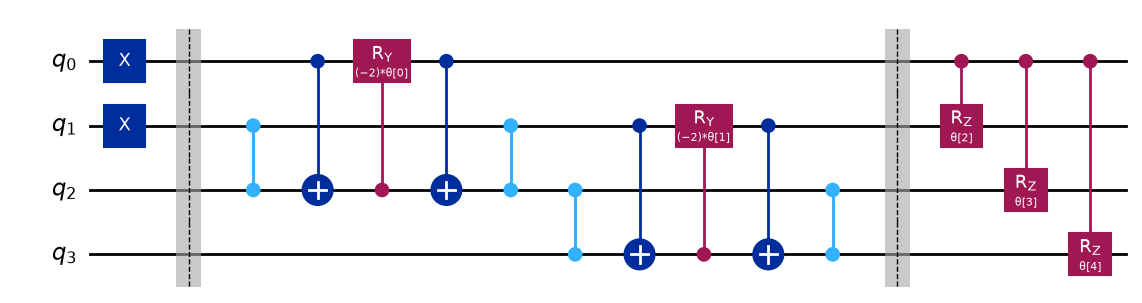

In [10]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector


# Define the variational parameters
theta_vector = ParameterVector("θ", 5)

# Build the ansatz
qc = QuantumCircuit(4)

# reference
qc.x(0)
qc.x(1)
qc.barrier()

# givens
add_givens_rotation(qc, 0, 2, theta=theta_vector[0])
add_givens_rotation(qc, 1, 3, theta=theta_vector[1])

qc.barrier()

# entanglement
add_entanglement_gate(qc, 0, 1, theta=theta_vector[2])
add_entanglement_gate(qc, 0, 2, theta=theta_vector[3])
add_entanglement_gate(qc, 0, 3, theta=theta_vector[4])


qc.draw('mpl')

In [11]:
from qiskit.primitives import StatevectorSampler
def cost_function(params, H_qubit):
    energy = 0.0
    for op, coeff in H_qubit.terms.items():

        qc_bound = qc.assign_parameters(params)

        qc_meas = qc_bound.copy()

        # set measurement basis
        for qi, pauli in op:
            if pauli == "X":
                qc_meas.h(qi)
            if pauli == "Y":
                qc_meas.rx(np.pi / 2, qi)
                #qc_meas.sdg(qi)
                #qc_meas.h(qi)

        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=100000).result()
        counts = result[0].data.meas.get_counts()
        # print(counts)

        shots = sum(counts.values())

        for bitstring, count in counts.items():

            parity = 1

            for qi, pauli in op:
                if bitstring[::-1][qi] == "1":
                    parity *= -1

            energy += parity * count / shots * coeff

    return energy.real

In [12]:
from openfermion import jordan_wigner, number_operator, s_squared_operator, sz_operator#

# define operators to measure
H_qubit = jordan_wigner(hamiltonian)
N = jordan_wigner(number_operator(4))
S2 = jordan_wigner(s_squared_operator(2))
Sz = jordan_wigner(sz_operator(2))

In [13]:
import numpy as np
from scipy.optimize import minimize

# Initial parameters
x0 = np.random.rand(5)

# Optimization
result = minimize(
    cost_function,
    x0,
    args=(H_qubit),
    method="COBYLA",
    options={"maxiter": 200,
             "disp": True,
             "rhobeg": 0.5,
             "tol": 1e-4,
    },
)

print("Optimal parameters:", result.x)
print("Minimum energy:", result.fun)

Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 66   Least value of F = -1.1173810997454323
The corresponding X is:
[ 0.00977637 -0.00147641  1.01290529  1.17257114  0.35232525]

Optimal parameters: [ 0.00977637 -0.00147641  1.01290529  1.17257114  0.35232525]
Minimum energy: -1.1173810997454323


In [14]:
print('Energy: {:.5f}'.format(cost_function(params=result.x, H_qubit=H_qubit)))
print('N electrons: {:.5f}'.format(cost_function(params=x0, H_qubit=N)))
print('Sz: {:.5f}'.format(cost_function(params=x0, H_qubit=Sz)))
print('S2: {:.5f}'.format(cost_function(params=x0, H_qubit=S2)))

Energy: -1.11675
N electrons: 1.99299
Sz: 0.00168
S2: 0.21046


## Custom ansatz construction

Using prior knowledge about the electronic structure of the ground state singlet of H2:

$ \alpha \  |0011 > + \beta \ |1100> \quad$ |  $\quad \alpha^2 + \beta^2 = 1 $

it is possible to create a circuit that implement this structure with a single variational parameter.

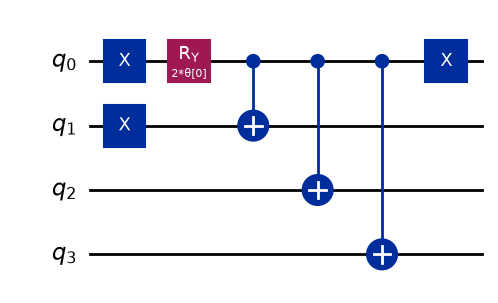

In [15]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector

# Define the variational parameters
theta_vector = ParameterVector("θ", 1)

# Build the ansatz
qc = QuantumCircuit(4)

# reference
qc.x(0)
qc.x(1)

qc.ry(2 * theta_vector[0], 0)

qc.cx(0, 1)
qc.cx(0, 2)
qc.cx(0, 3)

qc.x(0)

qc.draw('mpl')


In [16]:
import numpy as np
from scipy.optimize import minimize

# Initial parameters
x0 = np.random.rand(1)

# Optimization
result = minimize(
    cost_function,
    x0,
    args=(H_qubit),
    method="COBYLA",
    options={"maxiter": 200,
             "disp": True,
             "rhobeg": 0.5,
             "tol": 1e-4,
    },
)

print("Optimal parameters:", result.x)
print("Minimum energy:", result.fun)

Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 23   Least value of F = -1.1376514236883843
The corresponding X is: [1.46432361]

Optimal parameters: [1.46432361]
Minimum energy: -1.1376514236883843


In [17]:
print('Energy: {:.5f}'.format(cost_function(params=result.x, H_qubit=H_qubit)))
print('N electrons: {:.5f}'.format(cost_function(params=x0, H_qubit=N)))
print('Sz: {:.5f}'.format(cost_function(params=x0, H_qubit=Sz)))
print('S2: {:.5f}'.format(cost_function(params=x0, H_qubit=S2)))

Energy: -1.13749
N electrons: 2.00054
Sz: 0.00052
S2: -0.00016


## General Chemical Inspired ansatz (UCC)

### Exact implementation

In [18]:
from scipy.sparse.linalg import expm, expm_multiply

# a b a b a b
state = FermionOperator('0^ 1^')
H_sparse = get_sparse_operator(H_qubit, n_qubits=4)

def cost_function_exact(params):

    sparse_state = get_sparse_operator(state, n_qubits=4)

    T = params[0] * (FermionOperator('3^ 2^ 1 0 ') - FermionOperator('0^ 1^ 2 3')) # must be Hermitian
    t_qubit = jordan_wigner(T)

    for op in t_qubit.get_operators():
        sparse_op = get_sparse_operator(op, n_qubits=4)
        sparse_state = expm_multiply(sparse_op, sparse_state)

    return (sparse_state.T.conj() @ H_sparse @ sparse_state)[0, 0].real


In [19]:
import numpy as np
from scipy.optimize import minimize

# Initial parameters
x0 = np.random.rand(1)

# Optimization
result = minimize(
    cost_function_exact,
    x0,
    method="COBYLA",
    options={"maxiter": 200,
             "disp": True,
             "rhobeg": 0.5,
             "tol": 1e-4,
    },
)

print("Optimal parameters:", result.x)
print("Minimum energy:", result.fun)

Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 23   Least value of F = -1.1372838285710911
The corresponding X is: [0.11284326]

Optimal parameters: [0.11284326]
Minimum energy: -1.1372838285710911


### Implementation in a quantum circuit

In [20]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

def get_circuit(params):
    T = params[0] * (FermionOperator('3^ 2^ 1 0 ') - FermionOperator('0^ 1^ 2 3')) # must be Hermitian
    t_qubit = jordan_wigner(T)
    #print(t_qubit)

    # Build the ansatz
    qc = QuantumCircuit(4)

    qc.x(0)
    qc.x(1)

    i_op = 0
    for op, coef in t_qubit.terms.items():

        for qubit, pauli in op:
            if pauli == 'X':
                qc.h(qubit)
            elif pauli == 'Y':
                qc.rx(np.pi / 2, [qubit])

        for qubit, pauli in op[1:]:
            qc.cx(qubit, op[0][0])

        if len(op) > 0:
            qc.rz(2*coef.imag, op[0][0])

        for qubit, pauli in reversed(op[1:]):
            qc.cx(qubit, op[0][0])

        for qubit, pauli in op:
            if pauli == 'X':
                qc.h(qubit)
            elif pauli == 'Y':
                qc.rx(-np.pi / 2, [qubit])

        qc.barrier()

    #qc.draw('mpl')
    return qc

In [21]:
def cost_function(params, H_qubit):
    energy = 0.0
    for op, coeff in H_qubit.terms.items():

        qc_bound = get_circuit(params)

        qc_meas = qc_bound.copy()

        # set measurement basis
        for qi, pauli in op:
            if pauli == "X":
                qc_meas.h(qi)
            if pauli == "Y":
                qc_meas.rx(np.pi / 2, qi)
                #qc_meas.sdg(qi)
                #qc_meas.h(qi)

        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=100000).result()
        counts = result[0].data.meas.get_counts()
        # print(counts)

        shots = sum(counts.values())

        for bitstring, count in counts.items():

            parity = 1

            for qi, pauli in op:
                if bitstring[::-1][qi] == "1":
                    parity *= -1

            energy += parity * count / shots * coeff

    return energy.real

In [22]:
import numpy as np
from scipy.optimize import minimize

# Initial parameters
x0 = np.random.rand(1)

# Optimization
result = minimize(
    cost_function,
    x0,
    args=(H_qubit),
    method="COBYLA",
    options={"maxiter": 200,
             "disp": True,
             "rhobeg": 0.5,
             "tol": 1e-4,
    },
)

print("Optimal parameters:", result.x)
print("Minimum energy:", result.fun)

Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 24   Least value of F = -1.137603038255026
The corresponding X is: [-0.12037307]

Optimal parameters: [-0.12037307]
Minimum energy: -1.137603038255026


## Evaluation of molecular properties

In [23]:
print('Energy: {:.5f}'.format(cost_function(params=result.x, H_qubit=H_qubit)))
print('N electrons: {:.5f}'.format(cost_function(params=x0, H_qubit=N)))
print('Sz: {:.5f}'.format(cost_function(params=x0, H_qubit=Sz)))
print('S2: {:.5f}'.format(cost_function(params=x0, H_qubit=S2)))

Energy: -1.13729
N electrons: 1.99830
Sz: 0.00045
S2: 0.00173


Proposed exercises:
----------------------
1) Determine the possible outputs states prepared from the custom ansatz circuit for $\theta = 0$, $\theta = \pi/2$  and $\theta = \pi$.
2) Compare the VQE results from the different ansatz preparations. Which one is more efficient in terms of number of parameters and circuit depth? Which one is more accurate?